# 1. Импорт и анализ таблиц

1.1 Импорт данных

In [79]:
import pandas as pd  #выгружаю необходимые библиотеки
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

In [80]:
#выгружаю файл для работы, разделяя листы на отдельные фреймы
data=pd.read_excel('C:\\Users\\Gargulya1\\Desktop\\аналитик\\диплом\\Новый диплом датасет update.xlsx', sheet_name='Данные')
clients=pd.read_excel('C:\\Users\\Gargulya1\\Desktop\\аналитик\\диплом\\Новый диплом датасет update.xlsx', sheet_name='Clients')
city=pd.read_excel('C:\\Users\\Gargulya1\\Desktop\\аналитик\\диплом\\Новый диплом датасет update.xlsx', sheet_name='Region_dict')

1.2. EDA по таблице Данные

In [81]:
data.head()

,id_order,id_client,amt_payment,dtime_pay
0,100238,194569.0,5373.0,2022-07-17 21:48:15.896
1,100242,191056.0,4151.0,2022-07-07 03:09:39.699
2,100249,200049.0,5688.0,2022-07-29 13:25:59.976
3,100258,206161.0,4330.0,2022-08-15 22:55:02.538
4,100267,190945.0,5488.0,2022-07-05 19:46:47.174


In [82]:
data.shape  #изначальное количество строк

(37989, 4)

In [83]:
data.dtypes  #тип данных в столбцах соответствует колонкам

id_order                int64
id_client             float64
amt_payment           float64
dtime_pay      datetime64[ns]
dtype: object

In [84]:
data.isna().sum()  #пропусков нет только в идентификаторе покупки

id_order          0
id_client       588
amt_payment    2144
dtime_pay      2429
dtype: int64

In [85]:
data.loc[data['id_client'].isnull()]  #строк с пропусками по id_client только 1,5 %, и других сведений по ним тоже нет, - нужно удалить

,id_order,id_client,amt_payment,dtime_pay
61,100524,NaN,NaN,NaT
87,100645,NaN,NaN,NaT
88,100651,NaN,NaN,NaT
287,101672,NaN,NaN,NaT
308,101773,NaN,NaN,NaT
...,...,...,...,...
37782,296379,NaN,NaN,NaT
37891,297076,NaN,NaN,NaT
37927,297263,NaN,NaN,NaT
37970,297490,NaN,NaN,NaT


In [86]:
data.loc[data['amt_payment'].isnull()]  # пропусков по платежам 5,6 %, в свете анализа теста замена их на среднее или медианной значение или нули \
                                    #может исказить данные, нужно удалить

,id_order,id_client,amt_payment,dtime_pay
8,100285,195780.0,NaN,NaT
49,100471,203089.0,NaN,NaT
61,100524,NaN,NaN,NaT
87,100645,NaN,NaN,NaT
88,100651,NaN,NaN,NaT
...,...,...,...,...
37961,297452,191024.0,NaN,NaT
37969,297488,202717.0,NaN,NaT
37970,297490,NaN,NaN,NaT
37973,297502,201726.0,NaN,NaT


In [87]:
data.loc[data['dtime_pay'].isnull()] #пропусков по дате оплаты 6,4 %, тоже нужно удалить, т.к. сложно придумать правило, \
                                 #по которому можно восстановить пропущенные значения

,id_order,id_client,amt_payment,dtime_pay
8,100285,195780.0,NaN,NaT
49,100471,203089.0,NaN,NaT
61,100524,NaN,NaN,NaT
76,100594,183063.0,3338.0,NaT
87,100645,NaN,NaN,NaT
...,...,...,...,...
37961,297452,191024.0,NaN,NaT
37969,297488,202717.0,NaN,NaT
37970,297490,NaN,NaN,NaT
37973,297502,201726.0,NaN,NaT


In [88]:
rows_with_any_na = data.isna().any(axis=1).sum()  #строки хотя бы с одним пропуском
share_with_na = rows_with_any_na / len(data) * 100  #доля строк с пропусками

print(f"Всего строк: {len(data)}")
print(f"Строк с хотя бы одним пропуском: {rows_with_any_na}")
print(f"Доля строк с пропусками: {round(share_with_na,2)} %")

Всего строк: 37989
Строк с хотя бы одним пропуском: 2429
Доля строк с пропусками: 6.39 %


In [89]:
print(f"Пропуски пересекаются между собой, в целом составляют {round(share_with_na,2)} %, это менее 10 %. Удаление строк с пропусками приведёт\
 к незначительной потере объёма данных при улучшении качества и пригодности записей для анализа.")

Пропуски пересекаются между собой, в целом составляют 6.39 %, это менее 10 %. Удаление строк с пропусками приведёт к незначительной потере объёма данных при улучшении качества и пригодности записей для анализа.


In [90]:
df_clean = data.dropna().copy()  #создала очищенный от пропусков датафрейм
print(df_clean.isna().sum())  #проверяю, что пропусков не осталось

id_order       0
id_client      0
amt_payment    0
dtime_pay      0
dtype: int64


In [91]:
clients_dublicates= df_clean.duplicated(subset=['id_order']).sum()  #проверяю дубликаты по покупкам
if clients_dublicates ==0:
    print('Дубликаты по покупкам отсутствуют.')

Дубликаты по покупкам отсутствуют.


1.3. EDA по таблице Клиенты

In [92]:
clients.head()

,id_client,dtime_ad,nflag_test,id_trading_point
0,180844,2022-06-08 18:38:41.414,0,212
1,193942,NaT,0,13
2,226069,2022-07-11 16:28:38.511,1,54
3,183981,2022-06-16 12:23:59.289,1,991
4,322530,2022-07-08 08:56:08.714,0,1015


In [93]:
clients.dtypes  #тип данных в столбцах соответствует колонкам

id_client                    int64
dtime_ad            datetime64[ns]
nflag_test                   int64
id_trading_point             int64
dtype: object

In [94]:
clients.shape #смотрю количество строк

(55605, 4)

In [95]:
clients.isna().sum()  #смотрю есть ли пропуски

id_client             0
dtime_ad            249
nflag_test            0
id_trading_point      0
dtype: int64

In [96]:
print('Соотношение пропусков по колонке dtime_ad к общему количеству строк менее 1 %, могу удалить эти строки. Тем более, что я изучаю способ \
 воздействия на клиентские покупки, а отсутствуют данные о показе рекламного объявления.')

Соотношение пропусков по колонке dtime_ad к общему количеству строк менее 1 %, могу удалить эти строки. Тем более, что я изучаю способ  воздействия на клиентские покупки, а отсутствуют данные о показе рекламного объявления.


In [97]:
clients_clean=clients.dropna(subset=['dtime_ad'], inplace=False)  #удалила пустые строки и перепроверила
clients_clean.isna().sum()

id_client           0
dtime_ad            0
nflag_test          0
id_trading_point    0
dtype: int64

1.4. EDA по таблице Города

In [98]:
city.head()

,id_trading_point,city
0,1,Петрозаводск
1,2,Дмитров
2,4,Чехов
3,7,Ростов Великий
4,11,Владимир


In [99]:
city.shape #имеем 66 строк

(66, 2)

In [100]:
city.isna().sum()  #пропусков нет, данная таблица полностью устраивает

id_trading_point    0
city                0
dtype: int64

1.5. Исследование торговых точек

In [101]:
city_gr=city.groupby('city').agg(cnt_point=('id_trading_point','count')).reset_index()
city_gr  #посмотрю количество торговых точек в каждом городе

,city,cnt_point
0,Великий Новгород,1
1,Владимир,1
2,Волгоград,1
3,Дмитров,1
4,Казань,6
5,Краснодар,4
6,Красноярск,5
7,Москва,11
8,Мурманск,2
9,Нижний Новгород,1


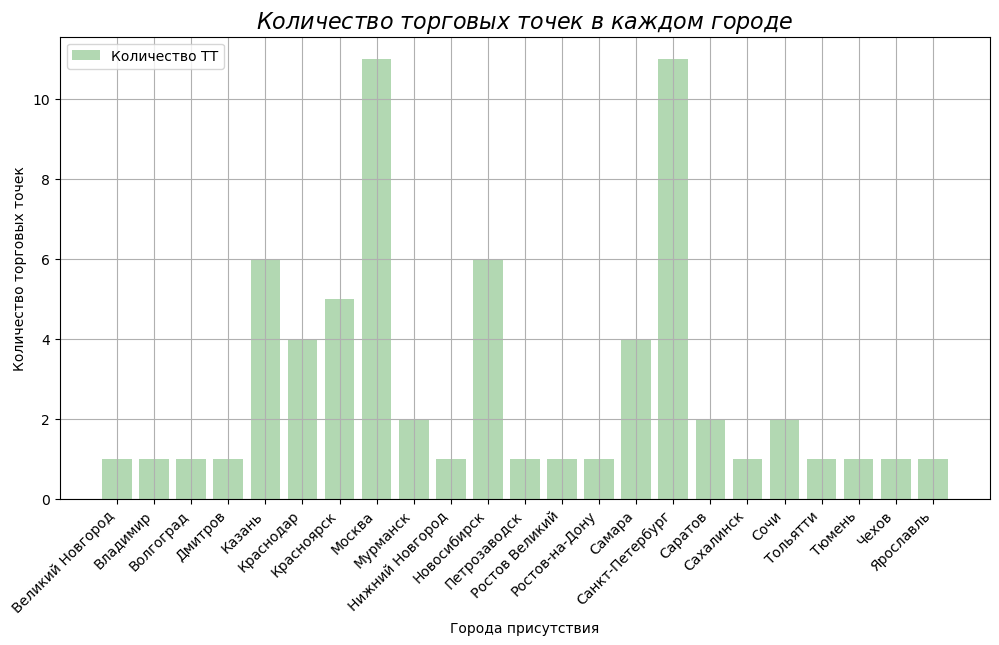

In [102]:
plt.figure(figsize=(12,6))  #визуализизация с помощью столбчатой диаграммы
plt.bar(city_gr['city'], city_gr['cnt_point'], alpha=.3, color='green', label='Количество ТТ')
plt.xlabel('Города присутствия')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.ylabel('Количество торговых точек')
plt.title('$Количество$ $торговых$ $точек$ $в$ $каждом$ $городе$', fontsize=16)
plt.legend(loc='upper left')
plt.grid()
plt.show()  

In [103]:
print('Больше всего торговых точек ретейлера SkyLenta в Москве и Санкт-Петербурге. Также среди городов присутствия выделяются на графике \
 Казань, Новосибирск, Самара, Краснодар и Красноярск. Три города, где по 2 тогровые точки (Мурманск, Саратов и Сочи), и в 13 городах наш \
  ретейлер представлен одной торговой точкой.')

Больше всего торговых точек ретейлера SkyLenta в Москве и Санкт-Петербурге. Также среди городов присутствия выделяются на графике  Казань, Новосибирск, Самара, Краснодар и Красноярск. Три города, где по 2 тогровые точки (Мурманск, Саратов и Сочи), и в 13 городах наш   ретейлер представлен одной торговой точкой.


# 2.Объединение таблиц

2.1. Агрегация платежей

In [104]:
clients_payment=(  #вычисляю сумму платежей на каждого клиента
    df_clean
    .groupby('id_client')
    .agg (sum_payment=('amt_payment','sum'))
    .reset_index()
)
clients_payment

,id_client,sum_payment
0,178561.0,3052.0
1,178562.0,2439.0
2,178563.0,768.0
3,178565.0,958.0
4,178566.0,5474.0
...,...,...
28378,209630.0,6927.0
28379,209631.0,2090.0
28380,209632.0,2775.0
28381,209633.0,1673.0


2.2. Объединение таблиц

In [105]:
rezult= pd.merge(clients_payment,clients_clean, on='id_client', how='outer')  #объединяю таблицы по клиентским платежам и данным клиентов
rezult

,id_client,sum_payment,dtime_ad,nflag_test,id_trading_point
0,178561.0,3052.0,2022-06-03 02:47:49.183,0,453
1,178562.0,2439.0,2022-06-03 02:51:21.878,0,2652
2,178563.0,768.0,2022-06-03 02:52:10.616,1,112
3,178564.0,NaN,2022-06-03 02:53:10.089,1,26
4,178565.0,958.0,2022-06-03 02:55:13.525,1,739
...,...,...,...,...,...
55351,331949.0,NaN,2022-07-15 10:07:09.632,1,573
55352,331950.0,NaN,2022-07-18 03:10:18.517,1,1654
55353,331954.0,NaN,2022-07-08 12:45:17.300,0,544
55354,331955.0,NaN,2022-08-12 03:15:49.011,0,72


In [106]:
print(len(clients_clean))  #убеждаюсь, что в таблице остались все клиенты из клиентской таблицы.
print(len(rezult))

55356
55356


In [107]:
rezult.isna().sum()  #по колонке сумма платежа образовались пропуски

id_client               0
sum_payment         26973
dtime_ad                0
nflag_test              0
id_trading_point        0
dtype: int64

In [108]:
rezult.fillna({'sum_payment':0}, inplace=True)  #заполнила пропуски нулями

In [109]:
rezult.isna().sum()  #перепроверила, пропусков нет

id_client           0
sum_payment         0
dtime_ad            0
nflag_test          0
id_trading_point    0
dtype: int64

2.3. Добавление данных

In [110]:
rezult_all= pd.merge(rezult,city, on='id_trading_point', how='left')  #подтянула наименования городов по торговым точкам, где они находятся
rezult_all.head()

,id_client,sum_payment,dtime_ad,nflag_test,id_trading_point,city
0,178561.0,3052.0,2022-06-03 02:47:49.183,0,453,Санкт-Петербург
1,178562.0,2439.0,2022-06-03 02:51:21.878,0,2652,Москва
2,178563.0,768.0,2022-06-03 02:52:10.616,1,112,Санкт-Петербург
3,178564.0,0.0,2022-06-03 02:53:10.089,1,26,Ростов-на-Дону
4,178565.0,958.0,2022-06-03 02:55:13.525,1,739,Новосибирск


In [111]:
rezult_all['flag_pay']=np.where(rezult_all['sum_payment']>=1,1,0)  #добавила поле флаг платежа
rezult_all

,id_client,sum_payment,dtime_ad,nflag_test,id_trading_point,city,flag_pay
0,178561.0,3052.0,2022-06-03 02:47:49.183,0,453,Санкт-Петербург,1
1,178562.0,2439.0,2022-06-03 02:51:21.878,0,2652,Москва,1
2,178563.0,768.0,2022-06-03 02:52:10.616,1,112,Санкт-Петербург,1
3,178564.0,0.0,2022-06-03 02:53:10.089,1,26,Ростов-на-Дону,0
4,178565.0,958.0,2022-06-03 02:55:13.525,1,739,Новосибирск,1
...,...,...,...,...,...,...,...
55351,331949.0,0.0,2022-07-15 10:07:09.632,1,573,Санкт-Петербург,0
55352,331950.0,0.0,2022-07-18 03:10:18.517,1,1654,Москва,0
55353,331954.0,0.0,2022-07-08 12:45:17.300,0,544,Казань,0
55354,331955.0,0.0,2022-08-12 03:15:49.011,0,72,Сочи,0


# 3. Автоматизация статистических вычислений

In [112]:
from scipy import stats  #понадобятся еще библиотеки
from scipy.stats import ttest_ind  
from scipy.stats import mannwhitneyu

In [113]:
def test_calc (r1, r2, alpha=0.05):  #функция для расчета критерия Стьюдента
    s, p=stats.ttest_ind (r1, r2)
    print(f"s: {s}")
    print(f"p_value: {p}")
    if p<=alpha:
        print('Нулевая гипотеза отвергается, разница статистически значима.')
    else:
        print('Нулевая гипотеза не отвергается, средние равны.')   
    return s, p

In [114]:
def mann_whitney_func (r1, r2, alpha=0.05):  #функция для расчета критерия Манна-Уитни
    u, p=mannwhitneyu (r1, r2)
    print(f"u: {u}")
    print(f"p_value: {p}")
    if p<=alpha:
        print('Нулевая гипотеза отвергается, разница статистически значима.')
    else:
        print('Нулевая гипотеза не отвергается, распределения равны.')
    return u, p

# 4. Удаление неверно заполненных точек

In [115]:
point_w_pay=[]  #список ТТ без платежей
for point in rezult_all['id_trading_point'].unique():  #цикл для выявления ТТ без платежей
    point_data = rezult_all[rezult_all['id_trading_point'] == point]
    control_sum = point_data.loc[point_data['nflag_test'] == 0, 'sum_payment'].sum()
    test_sum = point_data.loc[point_data['nflag_test'] == 1, 'sum_payment'].sum()
    if control_sum == 0 or test_sum == 0:
        point_w_pay.append(int(point))

print(f"Список торговых точек без платежей: {point_w_pay}")

Список торговых точек без платежей: [26, 739, 866, 46, 1099, 1015, 603, 810, 800, 228, 1, 13, 23, 4, 7]


In [116]:
point_w_group=[]  #список ТТ без обозначения групп тестирования
for point in rezult_all['id_trading_point'].unique():  #цикл для выявления ТТ без обозначения групп тестирования
    point_data = rezult_all[rezult_all['id_trading_point'] == point]
    control_gr = point_data[point_data['nflag_test'] == 0].shape[0]
    test_gr = point_data[point_data['nflag_test'] == 1].shape[0]
    if control_gr == 0 or test_gr == 0:
        point_w_group.append(int(point))

print(f"Список торговых точек без обозначения групп тестирования: {point_w_group}")

Список торговых точек без обозначения групп тестирования: [739, 866, 1099, 1015, 603, 810, 800, 228]


# 5. Расчет общих результатов А/В-теста

5.1. Результирующий датафрейм

In [117]:
df=rezult_all[~rezult_all['id_trading_point'].isin(point_w_pay) & ~rezult_all['id_trading_point'].isin(point_w_group)].copy()
#создала DF без ТТ из списков в пункте 4
df.head()

,id_client,sum_payment,dtime_ad,nflag_test,id_trading_point,city,flag_pay
0,178561.0,3052.0,2022-06-03 02:47:49.183,0,453,Санкт-Петербург,1
1,178562.0,2439.0,2022-06-03 02:51:21.878,0,2652,Москва,1
2,178563.0,768.0,2022-06-03 02:52:10.616,1,112,Санкт-Петербург,1
6,178567.0,2663.0,2022-06-03 03:02:56.855,0,453,Санкт-Петербург,1
7,178568.0,13537.0,2022-06-03 03:05:33.476,1,3786,Москва,1


5.2. Визуализация распределения платежей

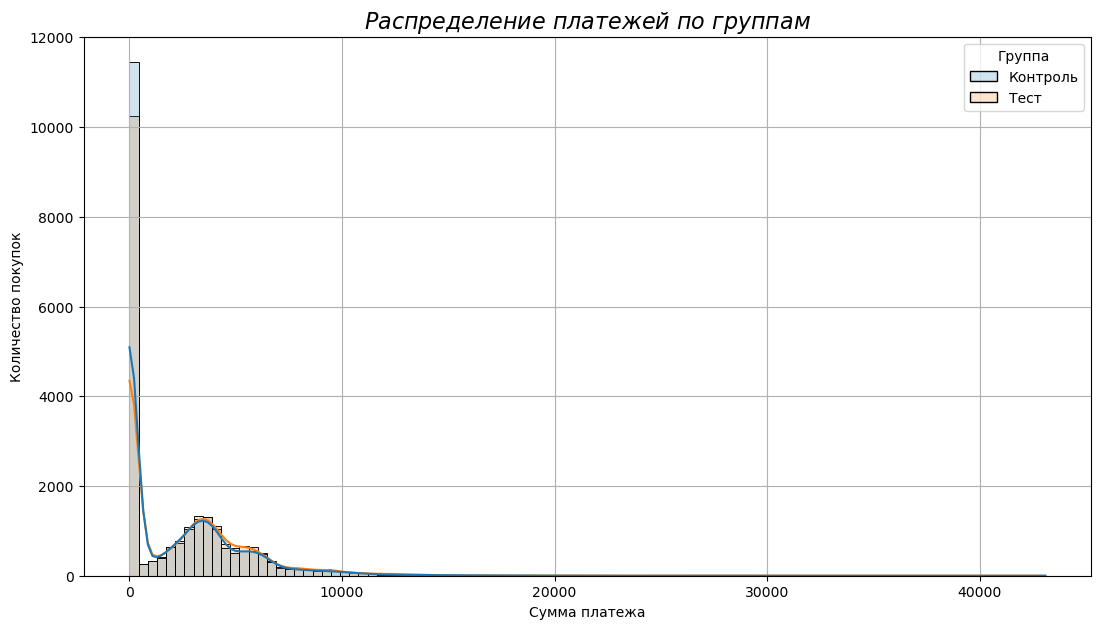

In [118]:
df_plot = df.copy()
df_plot['nflag_test'] = df_plot['nflag_test'].map({0: 'Контроль', 1: 'Тест'})  
#переназначаю названия групп в новом DF для последующей удобной визуализации легенды на графике

plt.figure(figsize=(13,7))  #визуализизация платежей по группам
ax=sns.histplot(df_plot, x='sum_payment', hue='nflag_test', bins=100, kde=True, alpha=0.2)
ax.get_legend().set_title('Группа')
plt.xlabel('Сумма платежа')
plt.ylabel('Количество покупок')
plt.title('$Распределение$ $платежей$ $по$ $группам$', fontsize=16)
plt.grid()
plt.show()

In [119]:
print('Вывод по гистограмме: у обоих групп значительная доля клиентов без платежей. Визуально распределение платежей у контрольной и тестовой групп\
похожи друг на друга. Также у обоих групп имеется длинный правый хвост, достигающий более 40 тысяч рублей. И основная масса платежей менее 5 тысяч.')

Вывод по гистограмме: у обоих групп значительная доля клиентов без платежей. Визуально распределение платежей у контрольной и тестовой групппохожи друг на друга. Также у обоих групп имеется длинный правый хвост, достигающий более 40 тысяч рублей. И основная масса платежей менее 5 тысяч.


5.3. Ручной подсчет показателей

In [120]:
df_gr=df.groupby('nflag_test').agg(cnt_obs=('id_client','count'),avg_payment=('sum_payment','mean'),cnt_pay=('flag_pay','sum')).reset_index()
df_gr['conv_pay']=df_gr['cnt_pay']/df_gr['cnt_obs']  #добавлю столбец с конверсией в покупку
df_gr  #сравню глазами показатели, которые будут учавствовать в тестировании

,nflag_test,cnt_obs,avg_payment,cnt_pay,conv_pay
0,0,22873,2189.188432,11431,0.499760
1,1,22445,2452.277345,12194,0.543284


In [121]:
print('Визуально в тестовой группе выше и средний чек и конверсия в покупку.')

Визуально в тестовой группе выше и средний чек и конверсия в покупку.


5.4. Т-тест

In [122]:
test_calc(df[df['nflag_test']==0]['sum_payment'],df[df['nflag_test']==1]['sum_payment'])
#применяю функцию t-теста к подготовленным данным по отношению к сумме клиентских платежей, чтобы сравнить их средние

s: -9.456798235171377
p_value: 3.3214645838934018e-21
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(-9.456798235171377), np.float64(3.3214645838934018e-21))

In [123]:
print('Вывод: t-тест показал, что гипотеза о равенстве средних платежей в контрольной и тестовой группах не подтверждается. \
P_value близка к нулю. С точки зрения среднего чека новый вид уведомлений более эффективен.')

Вывод: t-тест показал, что гипотеза о равенстве средних платежей в контрольной и тестовой группах не подтверждается. P_value близка к нулю. С точки зрения среднего чека новый вид уведомлений более эффективен.


In [124]:
test_calc(df[df['nflag_test']==0]['flag_pay'],df[df['nflag_test']==1]['flag_pay'])  
#применяю функцию t-теста к подготовленным данным по отношению к флагу платежа, чтобы сравнить конверсии в покупку

s: -9.282032730948323
p_value: 1.7338073027564523e-20
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(-9.282032730948323), np.float64(1.7338073027564523e-20))

In [125]:
print('Вывод: t-тест показал, что гипотеза о равенстве конверсий в покупку в контрольной и тестовой группах также не подтверждается. \
P_value близка к нулю. С точки зрения конверсии в покупку новый вид уведомлений также более эффективен.')

Вывод: t-тест показал, что гипотеза о равенстве конверсий в покупку в контрольной и тестовой группах также не подтверждается. P_value близка к нулю. С точки зрения конверсии в покупку новый вид уведомлений также более эффективен.


5.5. U-тест

In [126]:
mann_whitney_func(df[df['nflag_test']==0]['sum_payment'],df[df['nflag_test']==1]['sum_payment'])
#применяю функцию u-теста к подготовленным данным по отношению к сумме платежа, чтобы сравнить их распределение

u: 243344369.0
p_value: 3.008345273971901e-24
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(243344369.0), np.float64(3.008345273971901e-24))

In [127]:
print('Вывод: Расчет критерия Манна Уитни (u-тест) показал, что гипотеза о равенстве распределений платежей в контрольной и тестовой группах \
не подтверждается. Показатель p_value сопоставим с таким же в  t-тесте. С точки зрения среднего чека новый вид уведомлений более эффективен по \
результатам обоих тестов.')

Вывод: Расчет критерия Манна Уитни (u-тест) показал, что гипотеза о равенстве распределений платежей в контрольной и тестовой группах не подтверждается. Показатель p_value сопоставим с таким же в  t-тесте. С точки зрения среднего чека новый вид уведомлений более эффективен по результатам обоих тестов.


In [128]:
mann_whitney_func(df[df['nflag_test']==0]['flag_pay'],df[df['nflag_test']==1]['flag_pay'])
#применяю функцию u-теста к подготовленным данным по отношению к флагу платежа, чтобы сравнить распределение конверсий в покупку

u: 245519959.0
p_value: 1.8043406994299902e-20
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(245519959.0), np.float64(1.8043406994299902e-20))

In [129]:
print('U-тест показывает, что гипотеза о равенстве распределений конверсий в покупку в контрольной и тестовой группах \
не подтверждается. Показатель p_value сопоставим с таким же в  t-тесте. С точки зрения конверсии в покупку новый вид \
уведомлений более эффективен по результатам обоих тестов.')

U-тест показывает, что гипотеза о равенстве распределений конверсий в покупку в контрольной и тестовой группах не подтверждается. Показатель p_value сопоставим с таким же в  t-тесте. С точки зрения конверсии в покупку новый вид уведомлений более эффективен по результатам обоих тестов.


# 6. Сегментация результатов А/В-теста

6.1. Результаты А/В-тестирования по Москве

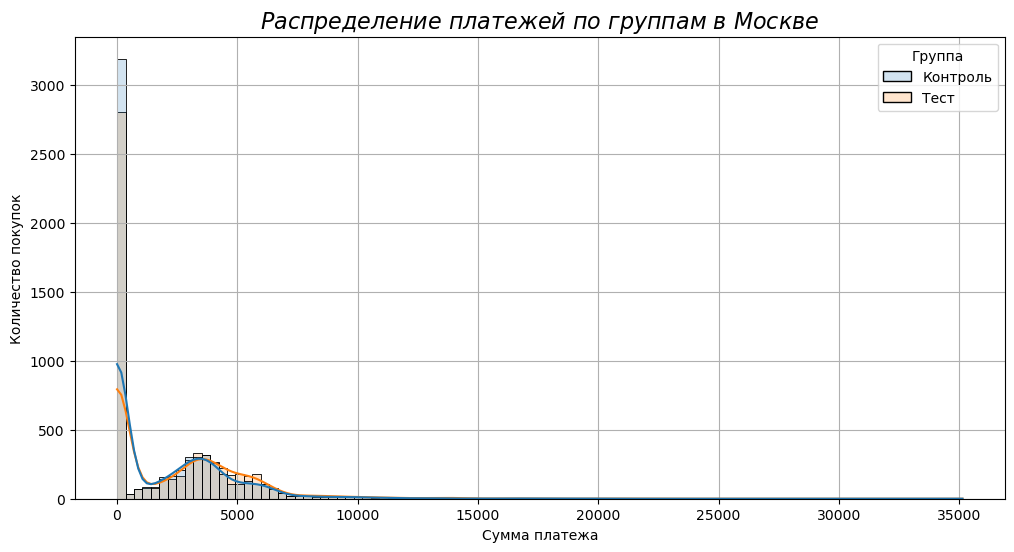

In [130]:
plt.figure(figsize=(12,6))  #визуализизация платежей по группам для клиентов из Москвы
df_moscow = df_plot[df_plot['city'] == 'Москва']
ax=sns.histplot(df_moscow, x='sum_payment', hue='nflag_test', bins=100, kde=True, alpha=0.2)
ax.get_legend().set_title('Группа')
plt.xlabel('Сумма платежа')
plt.ylabel('Количество покупок')
plt.title('$Распределение$ $платежей$ $по$ $группам$ $в$ $Москве$', fontsize=16)
plt.grid()
plt.show()

In [131]:
print('Не считая клиентов без платежей, основные платежи по Москве распределены в пределах 7-8 тысяч рублей. ')

Не считая клиентов без платежей, основные платежи по Москве распределены в пределах 7-8 тысяч рублей. 


In [132]:
test_calc(df[(df['nflag_test']==0)&(df['city']=='Москва')]['sum_payment'],\
          df[(df['nflag_test']==1)&(df['city']=='Москва')]['sum_payment'])
#применяю функцию t-теста к данным по отношению к сумме платежей для клиентов из Москвы, чтобы сравнить их средние

s: -7.676511027843395
p_value: 1.757549439555765e-14
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(-7.676511027843395), np.float64(1.757549439555765e-14))

In [133]:
test_calc(df[(df['nflag_test']==0)&(df['city']=='Москва')]['flag_pay'],\
          df[(df['nflag_test']==1)&(df['city']=='Москва')]['flag_pay'])  
#применяю функцию t-теста к данным по отношению к флагу платежа для клиентов из Москвы, чтобы сравнить конверсии в покупку

s: -6.190312288026297
p_value: 6.194689260032549e-10
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(-6.190312288026297), np.float64(6.194689260032549e-10))

In [134]:
mann_whitney_func(df[(df['nflag_test']==0)&(df['city']=='Москва')]['sum_payment'],\
                  df[(df['nflag_test']==1)&(df['city']=='Москва')]['sum_payment'])
#применяю функцию u-теста к данным по отношению к сумме платежа для клиентов из Москвы, чтобы сравнить их распределение

u: 17582441.5
p_value: 7.010591402203484e-16
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(17582441.5), np.float64(7.010591402203484e-16))

In [135]:
mann_whitney_func(df[(df['nflag_test']==0)&(df['city']=='Москва')]['flag_pay'],\
                  df[(df['nflag_test']==1)&(df['city']=='Москва')]['flag_pay'])
#применяю функцию u-теста к данным по отношению к флагу платежа для клиентов из Москвы, чтобы сравнить распределение конверсий в покупку

u: 18028079.0
p_value: 6.370381156613038e-10
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(18028079.0), np.float64(6.370381156613038e-10))

In [136]:
print('Вывод по Москве: t-тест и u-тест показывают, что гипотезы о равенстве средних платежей и распределений конверсий в покупку \
в контрольной и тестовой группах не подтверждаются. Показатель p_value во всех 4-х случаях стремится к нулю. С точек зрения и среднего чека и \
конверсии в покупку - новый вид уведомлений более эффективен по результатам обоих тестов.')

Вывод по Москве: t-тест и u-тест показывают, что гипотезы о равенстве средних платежей и распределений конверсий в покупку в контрольной и тестовой группах не подтверждаются. Показатель p_value во всех 4-х случаях стремится к нулю. С точек зрения и среднего чека и конверсии в покупку - новый вид уведомлений более эффективен по результатам обоих тестов.


6.2. Результаты А/В-тестирования по Санкт-Петербургу

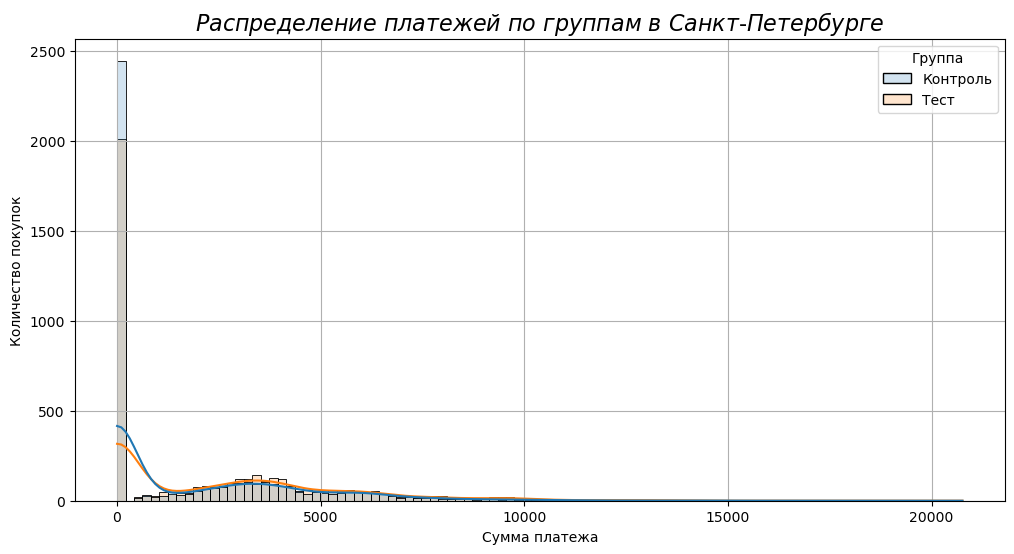

In [137]:
plt.figure(figsize=(12,6))  #визуализизация платежей по группам для клиентов из Санкт-Петербурга
df_spb = df_plot[df_plot['city'] == 'Санкт-Петербург']
ax=sns.histplot(df_spb, x='sum_payment', hue='nflag_test', bins=100, kde=True, alpha=0.2)
ax.get_legend().set_title('Группа')
plt.xlabel('Сумма платежа')
plt.ylabel('Количество покупок')
plt.title('$Распределение$ $платежей$ $по$ $группам$ $в$ $Санкт$-$Петербурге$', fontsize=16)
plt.grid()
plt.show()

In [138]:
print('Гистограмма по Санкт-Петербургу отличается от "московской", -она более пологая. Общее количество покупок меньше, количество клиентов \
без покупок меньше, и окончание правого хвоста лежит в других границах.')

Гистограмма по Санкт-Петербургу отличается от "московской", -она более пологая. Общее количество покупок меньше, количество клиентов без покупок меньше, и окончание правого хвоста лежит в других границах.


In [139]:
test_calc(df[(df['nflag_test']==0)&(df['city']=='Санкт-Петербург')]['sum_payment'],\
          df[(df['nflag_test']==1)&(df['city']=='Санкт-Петербург')]['sum_payment'])
#применяю функцию t-теста к данным по отношению к сумме платежей для клиентов из Санкт-Петербурга, чтобы сравнить их средние

s: -8.759635784179547
p_value: 2.3198088937974163e-18
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(-8.759635784179547), np.float64(2.3198088937974163e-18))

In [140]:
test_calc(df[(df['nflag_test']==0)&(df['city']=='Санкт-Петербург')]['flag_pay'],\
          df[(df['nflag_test']==1)&(df['city']=='Санкт-Петербург')]['flag_pay'])  
#применяю функцию t-теста к данным по отношению к флагу платежа для клиентов из Санкт-Петербурга, чтобы сравнить конверсии в покупку

s: -9.352468686561785
p_value: 1.065825659919673e-20
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(-9.352468686561785), np.float64(1.065825659919673e-20))

In [141]:
mann_whitney_func(df[(df['nflag_test']==0)&(df['city']=='Санкт-Петербург')]['sum_payment'],\
                  df[(df['nflag_test']==1)&(df['city']=='Санкт-Петербург')]['sum_payment'])
#применяю функцию u-теста к данным по отношению к сумме платежа для клиентов из Санкт-Петербурга, чтобы сравнить их распределение

u: 8809444.5
p_value: 2.0392184217953754e-20
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(8809444.5), np.float64(2.0392184217953754e-20))

In [142]:
mann_whitney_func(df[(df['nflag_test']==0)&(df['city']=='Санкт-Петербург')]['flag_pay'],\
                  df[(df['nflag_test']==1)&(df['city']=='Санкт-Петербург')]['flag_pay'])
#применяю функцию u-теста к данным по отношению к флагу платежа для клиентов из Санкт-Петербурга, чтобы сравнить распределение конверсий в покупку

u: 8881151.0
p_value: 1.3118606823466691e-20
Нулевая гипотеза отвергается, разница статистически значима.


(np.float64(8881151.0), np.float64(1.3118606823466691e-20))

In [143]:
print('Вывод по Санкт-Петербургу: хоть и количество покупок меньше, картина вырисовывается такая же, как и в Москве, -по результатам t-теста и \
u-теста разница везде статистически значима. Гипотезы о равенстве средних платежей и распределений конверсий в покупку в контрольной и тестовой \
группах не подтверждаются. Показатель p_value во всех 4-х случаях стремится к нулю. С точек зрения и среднего чека и конверсии в покупку -\
новый вид уведомлений более эффективен по результатам обоих тестов.')

Вывод по Санкт-Петербургу: хоть и количество покупок меньше, картина вырисовывается такая же, как и в Москве, -по результатам t-теста и u-теста разница везде статистически значима. Гипотезы о равенстве средних платежей и распределений конверсий в покупку в контрольной и тестовой группах не подтверждаются. Показатель p_value во всех 4-х случаях стремится к нулю. С точек зрения и среднего чека и конверсии в покупку -новый вид уведомлений более эффективен по результатам обоих тестов.


6.3. Результаты А/В-тестирования по другим городам

Саратов


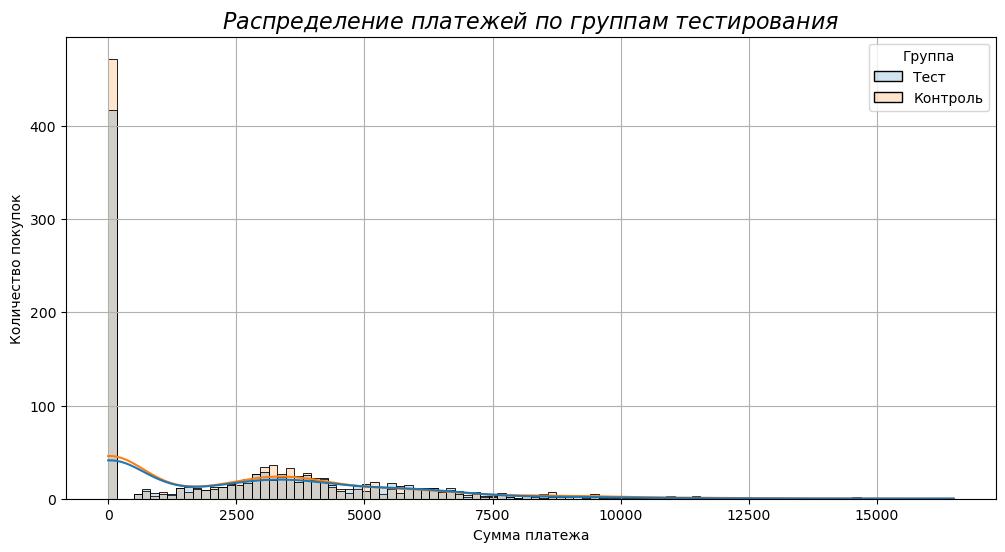

s: 0.10516947629572568
p_value: 0.9162512798549167
Нулевая гипотеза не отвергается, средние равны.
s: -0.6507850002388366
p_value: 0.5152558091282406
Нулевая гипотеза не отвергается, средние равны.
u: 557976.5
p_value: 0.7833257779753139
Нулевая гипотеза не отвергается, распределения равны.
u: 553867.0
p_value: 0.5151549688905628
Нулевая гипотеза не отвергается, распределения равны.

Тольятти


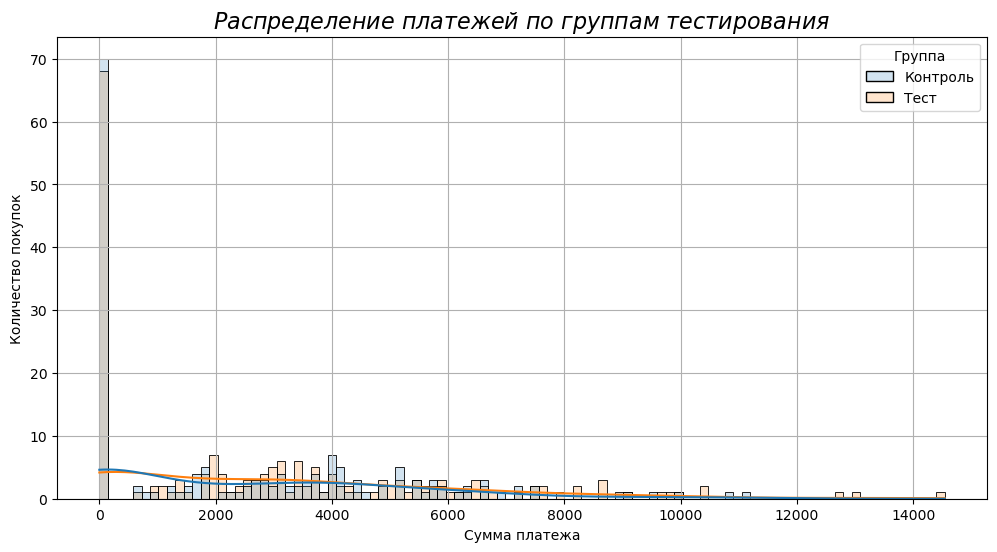

s: -1.5045563456740754
p_value: 0.1333273246710206
Нулевая гипотеза не отвергается, средние равны.
s: -1.185144360467606
p_value: 0.23675311799785542
Нулевая гипотеза не отвергается, средние равны.
u: 14709.5
p_value: 0.22134177144014489
Нулевая гипотеза не отвергается, распределения равны.
u: 14893.0
p_value: 0.2364676058329549
Нулевая гипотеза не отвергается, распределения равны.

Владимир


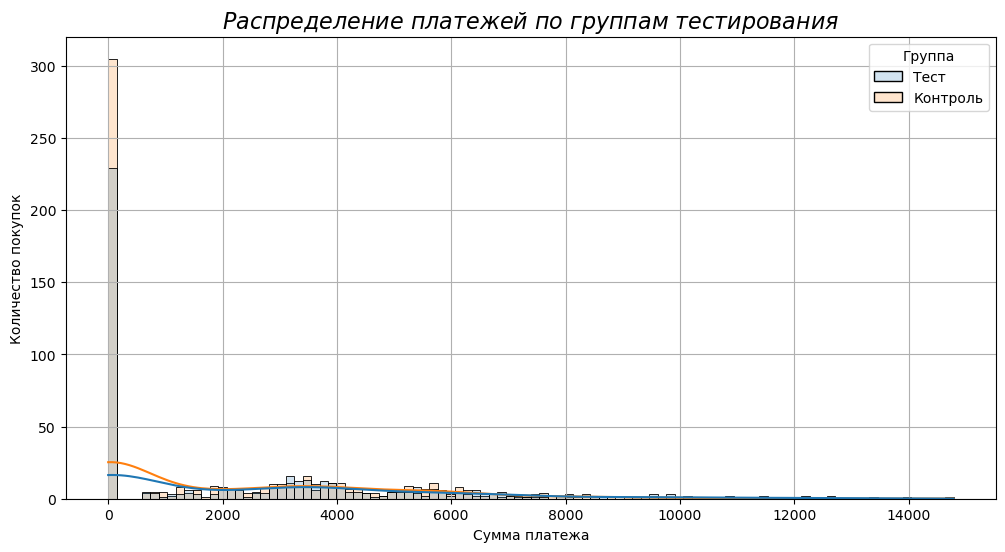

s: -2.5769554932923184
p_value: 0.010095112170351712
Нулевая гипотеза отвергается, разница статистически значима.
s: -1.724937016780416
p_value: 0.08481593543159477
Нулевая гипотеза не отвергается, средние равны.
u: 143847.0
p_value: 0.03166761411886426
Нулевая гипотеза отвергается, разница статистически значима.
u: 146729.5
p_value: 0.08483342425116364
Нулевая гипотеза не отвергается, распределения равны.

Мурманск


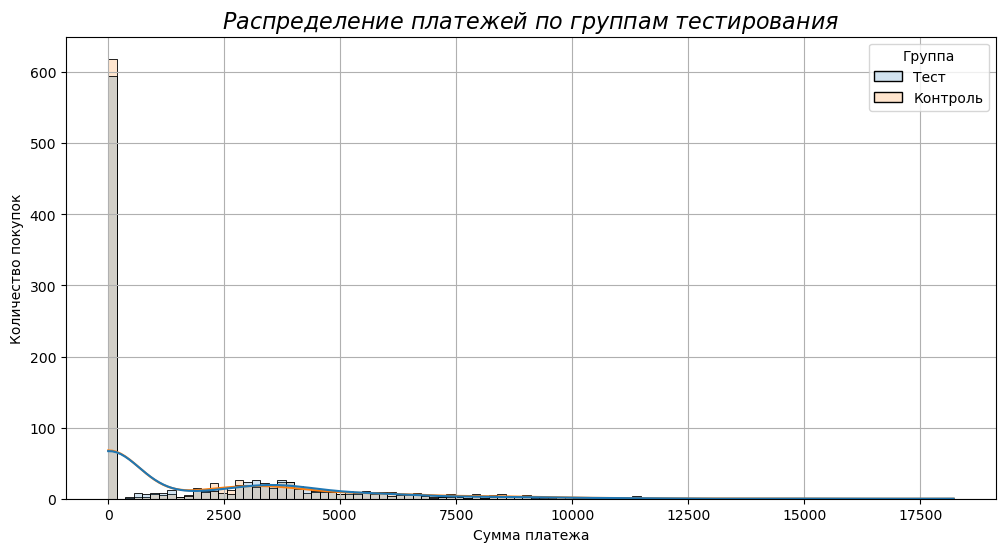

s: -0.06902498862889384
p_value: 0.9449762446327565
Нулевая гипотеза не отвергается, средние равны.
s: -0.8460108060373052
p_value: 0.3976422846466432
Нулевая гипотеза не отвергается, средние равны.
u: 554067.5
p_value: 0.5434251528583327
Нулевая гипотеза не отвергается, распределения равны.
u: 551570.0
p_value: 0.3975381533962302
Нулевая гипотеза не отвергается, распределения равны.

Красноярск


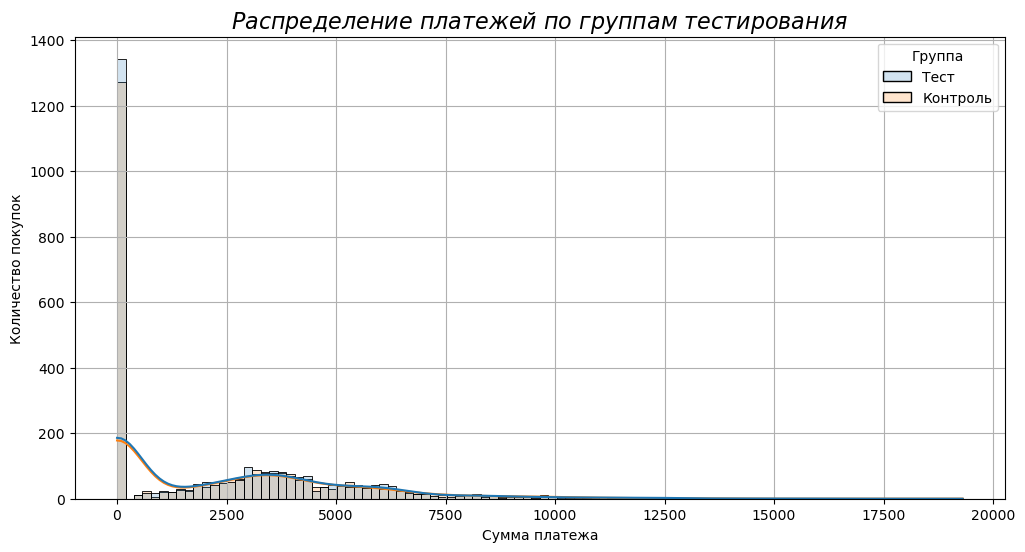

s: -0.12000608689929208
p_value: 0.9044823881233125
Нулевая гипотеза не отвергается, средние равны.
s: 0.27863631219717744
p_value: 0.7805336501430107
Нулевая гипотеза не отвергается, средние равны.
u: 4413418.0
p_value: 0.8770469886251647
Нулевая гипотеза не отвергается, распределения равны.
u: 4419468.0
p_value: 0.7805140863923713
Нулевая гипотеза не отвергается, распределения равны.

Казань


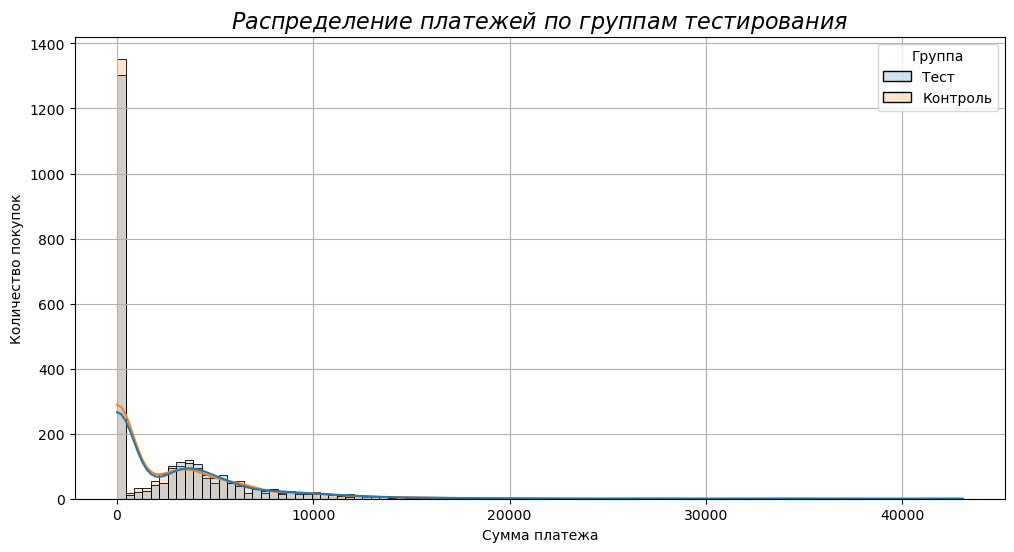

s: -1.0655273408818378
p_value: 0.286688049247618
Нулевая гипотеза не отвергается, средние равны.
s: -0.27304492857426443
p_value: 0.784829789025573
Нулевая гипотеза не отвергается, средние равны.
u: 3178575.0
p_value: 0.37726004167062477
Нулевая гипотеза не отвергается, распределения равны.
u: 3208915.5
p_value: 0.7848080524600568
Нулевая гипотеза не отвергается, распределения равны.

Самара


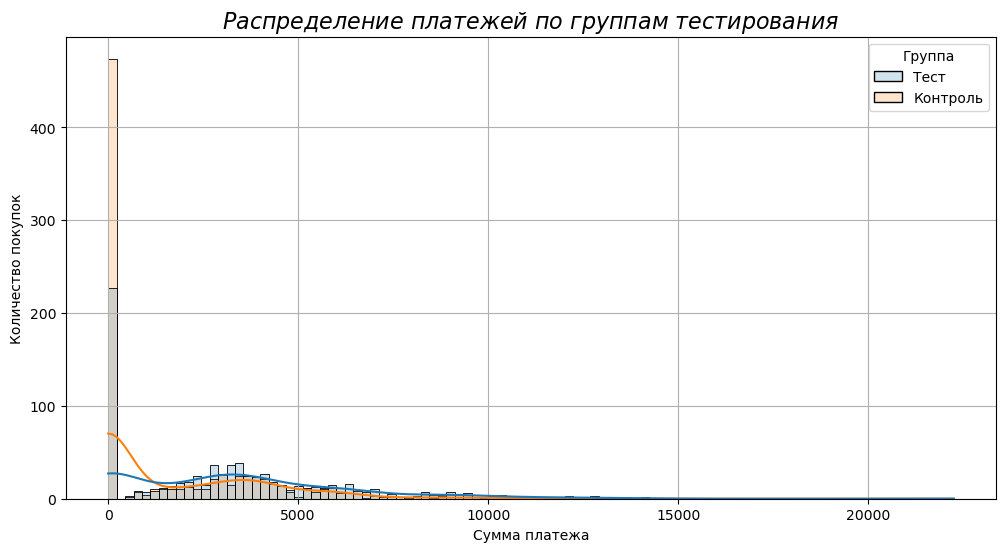

s: -11.54083248253458
p_value: 1.1014020778472052e-29
Нулевая гипотеза отвергается, разница статистически значима.
s: -11.846151689470245
p_value: 3.981449742682522e-31
Нулевая гипотеза отвергается, разница статистически значима.
u: 233516.5
p_value: 4.325201867794148e-30
Нулевая гипотеза отвергается, разница статистически значима.
u: 245193.0
p_value: 5.58808973496e-30
Нулевая гипотеза отвергается, разница статистически значима.

Волгоград


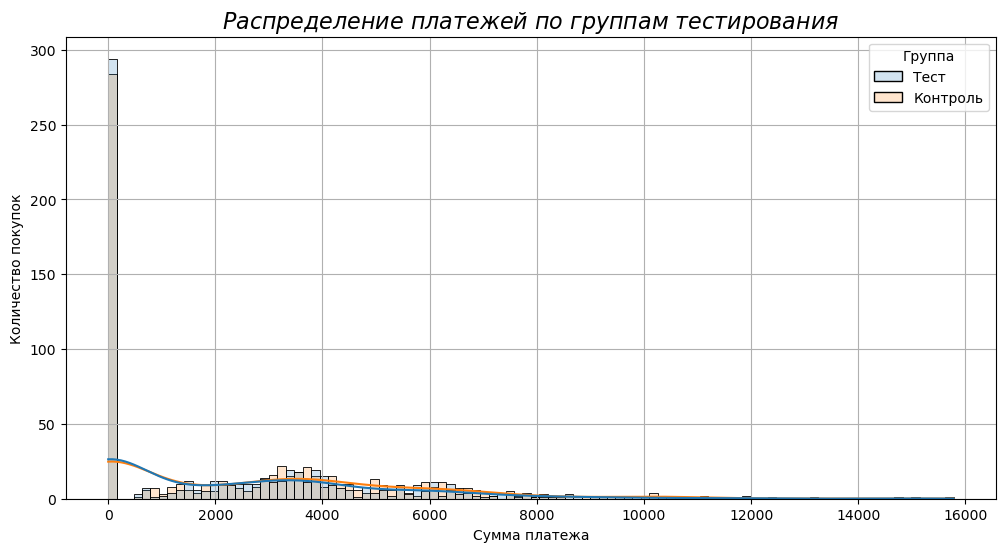

s: 2.0892718943323443
p_value: 0.03686899928098654
Нулевая гипотеза отвергается, разница статистически значима.
s: 1.6222173039489063
p_value: 0.10498894497258296
Нулевая гипотеза не отвергается, средние равны.
u: 245743.0
p_value: 0.03323940159324537
Нулевая гипотеза отвергается, разница статистически значима.
u: 240982.5
p_value: 0.10498253648223195
Нулевая гипотеза не отвергается, распределения равны.

Сочи


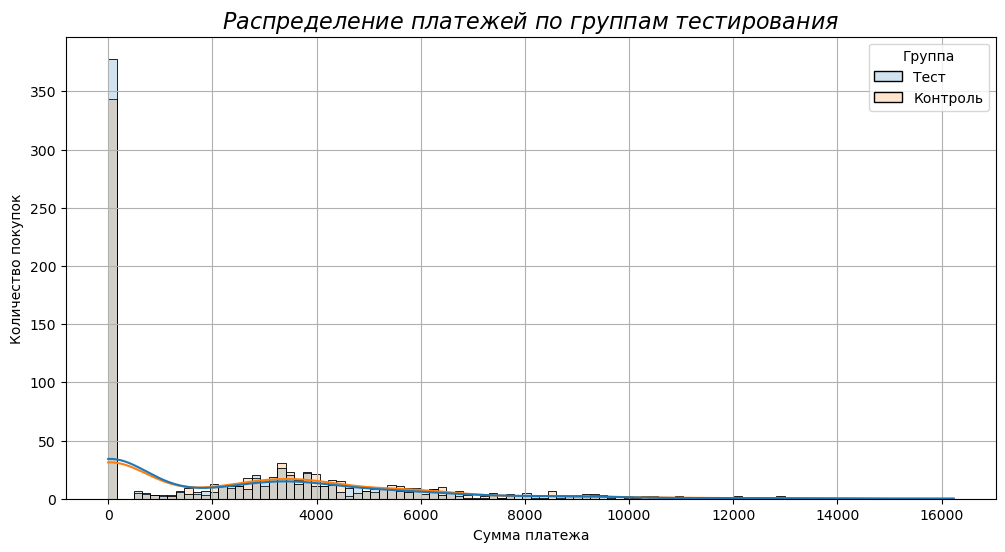

s: 1.5432162776667728
p_value: 0.12297605685687794
Нулевая гипотеза не отвергается, средние равны.
s: 1.9849560691617736
p_value: 0.047319885252583245
Нулевая гипотеза отвергается, разница статистически значима.
u: 337587.5
p_value: 0.05698257474271896
Нулевая гипотеза не отвергается, распределения равны.
u: 336608.0
p_value: 0.047359239516048784
Нулевая гипотеза отвергается, разница статистически значима.

Краснодар


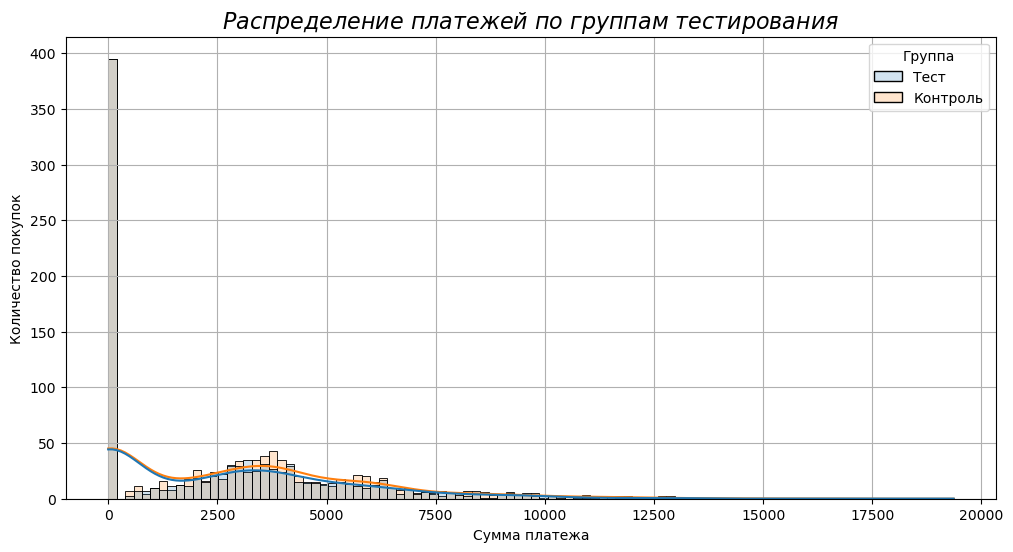

s: 1.718766529966594
p_value: 0.085800112916198
Нулевая гипотеза не отвергается, средние равны.
s: 1.8789539353324407
p_value: 0.06038527567849974
Нулевая гипотеза не отвергается, средние равны.
u: 609837.0
p_value: 0.05938101983441801
Нулевая гипотеза не отвергается, распределения равны.
u: 605880.5
p_value: 0.060406618664924146
Нулевая гипотеза не отвергается, распределения равны.

Дмитров


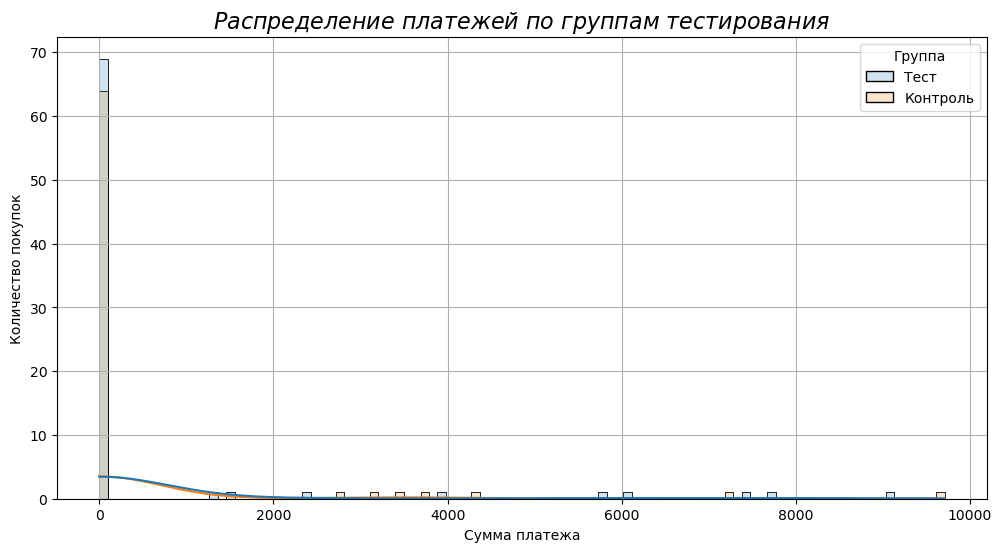

s: -0.3310524347645207
p_value: 0.7410763125801646
Нулевая гипотеза не отвергается, средние равны.
s: -0.3285782051097396
p_value: 0.7429421277261778
Нулевая гипотеза не отвергается, средние равны.
u: 2722.0
p_value: 0.7422551789442879
Нулевая гипотеза не отвергается, распределения равны.
u: 2722.5
p_value: 0.7444023199576546
Нулевая гипотеза не отвергается, распределения равны.

Тюмень


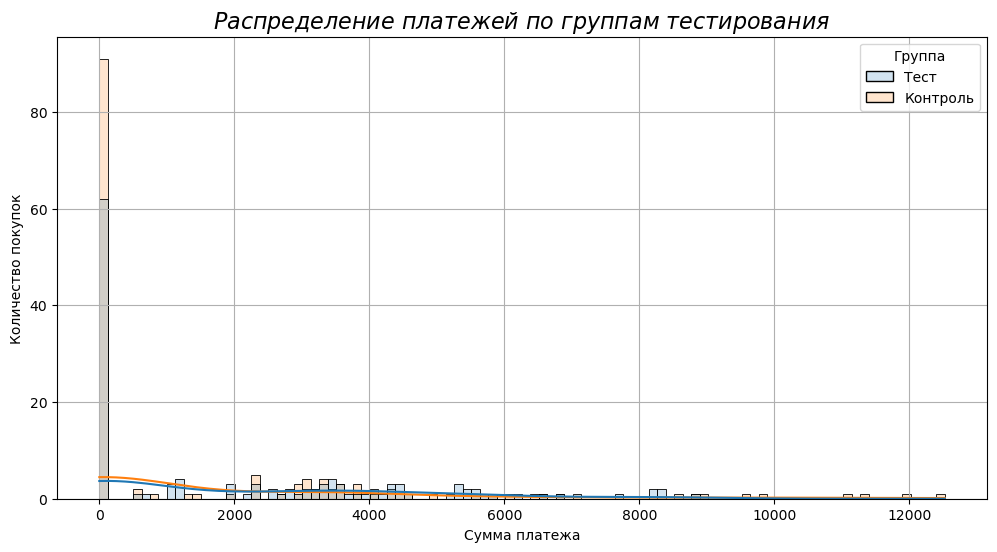

s: -0.9264590634677944
p_value: 0.3550227648604757
Нулевая гипотеза не отвергается, средние равны.
s: -2.4598250966325907
p_value: 0.01451825932213329
Нулевая гипотеза отвергается, разница статистически значима.
u: 8239.0
p_value: 0.038066216007540725
Нулевая гипотеза отвергается, разница статистически значима.
u: 8101.0
p_value: 0.014823398915456424
Нулевая гипотеза отвергается, разница статистически значима.

Сахалинск


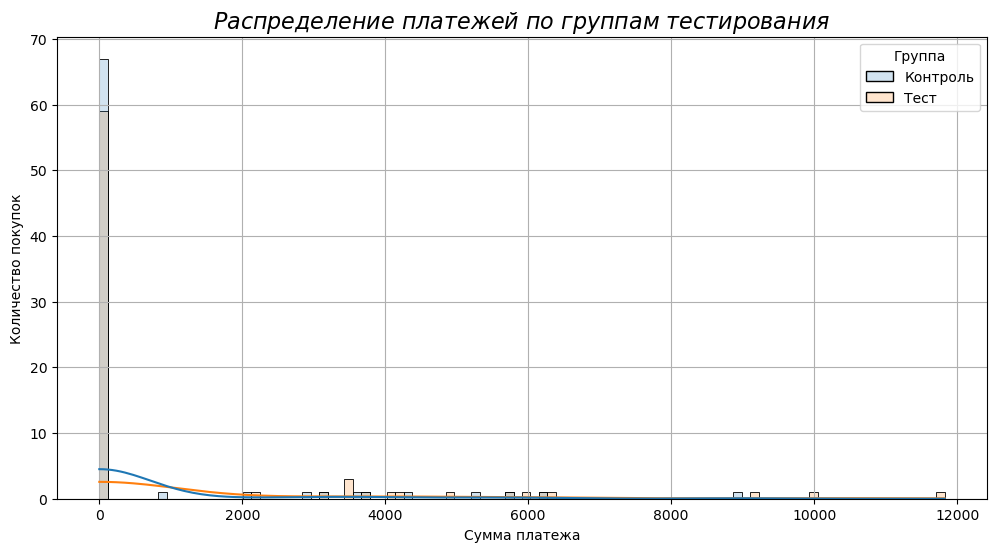

s: -1.6270604929283115
p_value: 0.105809212549273
Нулевая гипотеза не отвергается, средние равны.
s: -1.1704284638604745
p_value: 0.2436724740693643
Нулевая гипотеза не отвергается, средние равны.
u: 2690.5
p_value: 0.19868569514015844
Нулевая гипотеза не отвергается, распределения равны.
u: 2713.5
p_value: 0.24351609530716278
Нулевая гипотеза не отвергается, распределения равны.



In [144]:
excluded = {'Москва', 'Санкт-Петербург'}  #создала set городов, которые не будем брать в тестирование в цикле
for city in df['city'].unique():  #цикл для А/В-тестирования для других городов
    if city in excluded:
        continue  #пропускаем Москву и Спб
    df_city = df[df['city'] == city]
    print (city)

    plt.figure(figsize=(12,6))  #визуализизация платежей по группам для клиентов по городам
    df_any_city = df_plot[df_plot['city'] == city]
    ax=sns.histplot(df_any_city, x='sum_payment', hue='nflag_test', bins=100, kde=True, alpha=0.2)
    ax.get_legend().set_title('Группа')
    plt.xlabel('Сумма платежа')
    plt.ylabel('Количество покупок')
    plt.title('$Распределение$ $платежей$ $по$ $группам$ $тестирования$', fontsize=16)
    plt.grid()
    plt.show()

    test_calc(df_city[(df_city['nflag_test']==0)&(df_city['city']==city)]['sum_payment'],\
          df_city[(df_city['nflag_test']==1)&(df_city['city']==city)]['sum_payment'])  #средние по платежам
    test_calc(df_city[(df_city['nflag_test']==0)&(df_city['city']==city)]['flag_pay'],\
          df_city[(df_city['nflag_test']==1)&(df_city['city']==city)]['flag_pay'])  #средние по конверсии
    mann_whitney_func(df_city[(df_city['nflag_test']==0)&(df_city['city']==city)]['sum_payment'],\
                  df_city[(df_city['nflag_test']==1)&(df_city['city']==city)]['sum_payment'])  #распределение по платежам
    mann_whitney_func(df_city[(df_city['nflag_test']==0)&(df_city['city']==city)]['flag_pay'],\
                  df_city[(df_city['nflag_test']==1)&(df_city['city']==city)]['flag_pay'])  #распределение по конверсии
    print()

In [145]:
print('В восьми городах присутствия ресейла - Саратов, Тольяти , Мурманск, Красноярск, Казань, Краснодар, Дмитров, Южно-Сахалинск -по результатам \
t-теста и u-теста разница везде статистически незначима. Гипотезы о равенстве средних платежей и распределений конверсий в покупку в контрольной \
и тестовой группах подтверждаются. Показатель p_value во всех 4-х случаях больше уровня значимости. С точек зрения и среднего чека и конверсии \
в покупку -новый вид пуш-уведомлений не был более эффективен по результатам обоих тестов, чем уведомление в форме баннера.')

В восьми городах присутствия ресейла - Саратов, Тольяти , Мурманск, Красноярск, Казань, Краснодар, Дмитров, Южно-Сахалинск -по результатам t-теста и u-теста разница везде статистически незначима. Гипотезы о равенстве средних платежей и распределений конверсий в покупку в контрольной и тестовой группах подтверждаются. Показатель p_value во всех 4-х случаях больше уровня значимости. С точек зрения и среднего чека и конверсии в покупку -новый вид пуш-уведомлений не был более эффективен по результатам обоих тестов, чем уведомление в форме баннера.


In [146]:
print('В Самаре t-тест и u-тест показывают, что гипотезы о равенстве средних платежей и распределений конверсий в покупку в контрольной и \
тестовой группах не подтверждаются. Показатель p_value во всех 4-х случаях стремится к нулю. С точек зрения и среднего чека и конверсии \
в покупку - новый вид уведомлений более эффективен по результатам обоих тестов.')

В Самаре t-тест и u-тест показывают, что гипотезы о равенстве средних платежей и распределений конверсий в покупку в контрольной и тестовой группах не подтверждаются. Показатель p_value во всех 4-х случаях стремится к нулю. С точек зрения и среднего чека и конверсии в покупку - новый вид уведомлений более эффективен по результатам обоих тестов.


In [147]:
print('В Владимире и Волгограде гипотеза о равенстве средних платежей в контрольной и тестовой группах не подтверждаются. С точки зрения \
среднего чека новый вид уведомлений более эффективен по результатам обоих тестов. А тестирование распределений конверсий в покупку обоими\
способами показало, что на конверсию в покупку изменение вида уведомления не влияло. Нулевая гипотеза не отвергается.')

В Владимире и Волгограде гипотеза о равенстве средних платежей в контрольной и тестовой группах не подтверждаются. С точки зрения среднего чека новый вид уведомлений более эффективен по результатам обоих тестов. А тестирование распределений конверсий в покупку обоимиспособами показало, что на конверсию в покупку изменение вида уведомления не влияло. Нулевая гипотеза не отвергается.


In [148]:
print('В Сочи наоборот гипотеза о равенстве средних платежей в контрольной и тестовой группах не отвергается. С точки зрения среднего чека \
новый вид уведомлений не был эффективен по результатам обоих тестов. А тестирование конверсии в покупку обоими способами показало, \
что на конверсию в покупку изменение вида уведомления повлияло. Нулевая гипотеза отвергается, разница статистически значима.')

В Сочи наоборот гипотеза о равенстве средних платежей в контрольной и тестовой группах не отвергается. С точки зрения среднего чека новый вид уведомлений не был эффективен по результатам обоих тестов. А тестирование конверсии в покупку обоими способами показало, что на конверсию в покупку изменение вида уведомления повлияло. Нулевая гипотеза отвергается, разница статистически значима.


In [149]:
print('В Тюмени картина специфична. По результатам t-теста  гипотеза о равенстве средних платежей в контрольной и тестовой группах не отвергается.\
Средний чек значимо не изменился. При этом тест Манна-Уитни показывает значимое различие распределений по обоим показателям. Это может означать, \
что эффект затронул не среднее, а форму распределения платежей — ,например, медиану или хвост распределения. Так как платежи имеют тяжёлые \
хвосты и t-тест чувствителен к выбросам, для платежей более показательным считаем результат теста Манна-Уитни.')

В Тюмени картина специфична. По результатам t-теста  гипотеза о равенстве средних платежей в контрольной и тестовой группах не отвергается.Средний чек значимо не изменился. При этом тест Манна-Уитни показывает значимое различие распределений по обоим показателям. Это может означать, что эффект затронул не среднее, а форму распределения платежей — ,например, медиану или хвост распределения. Так как платежи имеют тяжёлые хвосты и t-тест чувствителен к выбросам, для платежей более показательным считаем результат теста Манна-Уитни.


# 7. Отчет по А/В-тесту

7.1. Создание датафрейма

In [150]:
df['nflag_test'] = df['nflag_test'].astype(int)  #поменяла тип данных для корректного подсчета далее
df.info()  #проверила

<class 'pandas.core.frame.DataFrame'>
Index: 45318 entries, 0 to 55355
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id_client         45318 non-null  float64       
 1   sum_payment       45318 non-null  float64       
 2   dtime_ad          45318 non-null  datetime64[ns]
 3   nflag_test        45318 non-null  int64         
 4   id_trading_point  45318 non-null  int64         
 5   city              45318 non-null  object        
 6   flag_pay          45318 non-null  int64         
dtypes: datetime64[ns](1), float64(2), int64(3), object(1)
memory usage: 2.8+ MB


In [151]:
total_obs = len(df)   # все наблюдения ресейла
rows = []  #создала список для строки

#имеем данные на уровне клиентов, а пересобираем , агрегируя по торговым точкам 
for tt in df['id_trading_point'].unique():  #цикл для строк датафрейма по торговым точкам
    tt_data= df[df['id_trading_point'] == tt]  #срез данныз по конкретной торговой точке
    city = tt_data['city'].iloc[0]  # город одинаковый внутри точки

    test_data = tt_data[tt_data['nflag_test'] == 1]['sum_payment']  #разделила данные по группам с учетом колонки по платежам, которая понадобится
    control_data = tt_data[tt_data['nflag_test'] == 0]['sum_payment']  #для дальнейших расчетов

    count_test = len(test_data)  #задаю содержимое колонок согласно задаче
    count_control = len(control_data)
    count_all = count_test + count_control
    percent_count = round((count_all/total_obs) * 100, 2)

    avg_payment_test = test_data.mean()
    avg_payment_control = control_data.mean()
    diff = avg_payment_test - avg_payment_control

    sigma_test = test_data.std()
    sigma_control = control_data.std()

    s, p=stats.ttest_ind (test_data, control_data)
    
    rows.append({  #собираю список строки в порядке будущих колонок
            'city': city,
            'id_trading_point': tt,
            'count_test': count_test,
            'count_control': count_control,
            'count_all': count_all,
            'percent_count': percent_count,
            'avg_payment_test': avg_payment_test,
            'avg_payment_control': avg_payment_control,
            'diff': diff,
            'sigma_test': sigma_test,
            'sigma_control': sigma_control,
            'ttest': s,
            'pvalue_ttest': p
        })
df_data_export=pd.DataFrame(rows,columns=[
    'city','id_trading_point','count_test','count_control','count_all','percent_count','avg_payment_test',\
    'avg_payment_control','diff','sigma_test','sigma_control','ttest','pvalue_ttest'
])  #создала датафрейм с заданными колонками
df_data_export

,city,id_trading_point,count_test,count_control,count_all,percent_count,avg_payment_test,avg_payment_control,diff,sigma_test,sigma_control,ttest,pvalue_ttest
0,Санкт-Петербург,453,1066,1049,2115,4.67,2501.966229,1889.923737,612.042492,2993.442540,2648.659303,4.976910,6.983207e-07
1,Москва,2652,2273,2370,4643,10.25,2506.616806,1972.847679,533.769127,2842.182948,2565.878242,6.722230,2.005922e-11
2,Санкт-Петербург,112,652,683,1335,2.95,2488.115031,2218.636896,269.478135,2778.179183,2780.790660,1.770712,7.683710e-02
3,Москва,3786,237,278,515,1.14,2613.683544,2688.230216,-74.546672,2712.235859,3292.937641,-0.277399,7.815857e-01
4,Санкт-Петербург,117,625,587,1212,2.67,2582.297600,2050.691652,531.605948,2835.004503,2595.737792,3.398196,7.003817e-04
5,Саратов,80,844,880,1724,3.80,2517.330569,2511.972727,5.357841,2797.123033,2824.719932,0.039558,9.684500e-01
6,Тольятти,88,190,167,357,0.79,2902.410526,2439.461078,462.949448,3074.648887,2689.343053,1.504556,1.333273e-01
7,Владимир,11,509,608,1117,2.46,2547.220039,2108.610197,438.609842,3023.702164,2663.038392,2.576955,1.009511e-02
8,Мурманск,55,422,425,847,1.87,2109.106635,2111.272941,-2.166306,2790.993385,2804.223188,-0.011268,9.910125e-01
9,Красноярск,212,593,575,1168,2.58,2144.317032,2222.052174,-77.735142,2708.588724,2785.116250,-0.483585,6.287709e-01


In [152]:
condlist=[  #использую метод np.select для добавления колонки с лейблом, т.к. много условий
    (df_data_export['diff']>0)&(df_data_export['pvalue_ttest']<0.05),
    (df_data_export['diff']<0)&(df_data_export['pvalue_ttest']<0.05)
]
choicelist=['положительный исход','отрицательный исход']
default='нейтральный исход'
df_data_export['label']=np.select(condlist, choicelist, default)
df_data_export     

,city,id_trading_point,count_test,count_control,count_all,percent_count,avg_payment_test,avg_payment_control,diff,sigma_test,sigma_control,ttest,pvalue_ttest,label
0,Санкт-Петербург,453,1066,1049,2115,4.67,2501.966229,1889.923737,612.042492,2993.442540,2648.659303,4.976910,6.983207e-07,положительный исход
1,Москва,2652,2273,2370,4643,10.25,2506.616806,1972.847679,533.769127,2842.182948,2565.878242,6.722230,2.005922e-11,положительный исход
2,Санкт-Петербург,112,652,683,1335,2.95,2488.115031,2218.636896,269.478135,2778.179183,2780.790660,1.770712,7.683710e-02,нейтральный исход
3,Москва,3786,237,278,515,1.14,2613.683544,2688.230216,-74.546672,2712.235859,3292.937641,-0.277399,7.815857e-01,нейтральный исход
4,Санкт-Петербург,117,625,587,1212,2.67,2582.297600,2050.691652,531.605948,2835.004503,2595.737792,3.398196,7.003817e-04,положительный исход
5,Саратов,80,844,880,1724,3.80,2517.330569,2511.972727,5.357841,2797.123033,2824.719932,0.039558,9.684500e-01,нейтральный исход
6,Тольятти,88,190,167,357,0.79,2902.410526,2439.461078,462.949448,3074.648887,2689.343053,1.504556,1.333273e-01,нейтральный исход
7,Владимир,11,509,608,1117,2.46,2547.220039,2108.610197,438.609842,3023.702164,2663.038392,2.576955,1.009511e-02,положительный исход
8,Мурманск,55,422,425,847,1.87,2109.106635,2111.272941,-2.166306,2790.993385,2804.223188,-0.011268,9.910125e-01,нейтральный исход
9,Красноярск,212,593,575,1168,2.58,2144.317032,2222.052174,-77.735142,2708.588724,2785.116250,-0.483585,6.287709e-01,нейтральный исход


In [153]:
df_data_export['label'].value_counts()  #посмотрела количество исходов

label
нейтральный исход      31
положительный исход    17
отрицательный исход     3
Name: count, dtype: int64

7.2. Перенос в документ Excel

In [154]:
pip install xlsxwriter 

Note: you may need to restart the kernel to use updated packages.


In [155]:
df_pos=df_data_export[df_data_export['label']=='положительный исход'].copy()  #разделила DF на будущие листы 
df_neg=df_data_export[df_data_export['label']=='отрицательный исход'].copy()
df_neu=df_data_export[df_data_export['label']=='нейтральный исход'].copy()

In [156]:
#создаю файл и записываю листы
with pd.ExcelWriter(r'C:\Users\Gargulya1\Desktop\аналитик\диплом\calculyator.xlsx',engine='xlsxwriter') as writer:
    df_pos.to_excel(writer, sheet_name='Положительные исходы', index=False)
    df_neg.to_excel(writer, sheet_name='Отрицательные исходы', index=False)
    df_neu.to_excel(writer, sheet_name='Нейтральные исходы', index=False)